# 库存 ABC 分类分析

本项目基于英国一家线上礼品批发零售商的真实交易数据，对商品进行 ABC 帕累托分类，识别贡献主要销售额的核心商品，并为不同类别的商品提出差异化的库存管理建议。

- **数据来源**：UCI Machine Learning Repository — Online Retail II（CC BY 4.0）
- **数据范围**：2010 年 12 月至 2011 年 12 月，共 541,910 条交易记录
- **使用工具**：Python（pandas、matplotlib）

## 1. 数据读取与探索

读取数据，查看数据规模、字段含义和数据类型，初步了解数据中是否存在缺失值。

In [1]:
import pandas as pd

df = pd.read_excel("data/online_retail_II.xlsx", sheet_name="Year 2010-2011")

In [2]:
# shape 返回一个括号：(行数, 列数)，用来快速了解数据有多大
print(df.shape)

# head() 显示前 5 行，相当于在 Excel 里瞄一眼表格开头
# 放在单元格最后一行，Jupyter 会自动把它显示成整齐的表格
df.head()

(541910, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
# info() 会列出：
#   - 每一列的名字
#   - 每一列"非空值"的数量（如果比总行数少，说明这一列有缺失值）
#   - 每一列的数据类型（int 整数 / float 小数 / object 文字 / datetime 日期时间）
# 作用类似 R 里的 str()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      541910 non-null  object        
 1   StockCode    541910 non-null  object        
 2   Description  540456 non-null  object        
 3   Quantity     541910 non-null  int64         
 4   InvoiceDate  541910 non-null  datetime64[ns]
 5   Price        541910 non-null  float64       
 6   Customer ID  406830 non-null  float64       
 7   Country      541910 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


## 2. 数据质量检查

在清洗之前，先统计各类问题数据的数量，而不是直接删除。除了缺失值，还需要检查那些"有值但不合理"的记录：取消订单、数量或价格为负数或零、重复记录，以及运费、手续费等非商品记录。

非商品编号是通过"编号不以数字开头"这一规则筛选出来后，再逐一人工判断的。规则会误伤部分真实商品（如派对礼包、靠垫填充物），因此不能只依赖自动规则。

In [4]:
# ===== 第 2 步（上）：检查各类问题数据有多少条，暂时不删除 =====

# 1. 每一列有多少个缺失值
#    isnull() 把空格子标成 True，sum() 数出每列有几个 True
print("各列缺失值数量：")
print(df.isnull().sum())

# 2. 取消的订单：发票号以字母 C 开头
#    astype(str) 先把发票号转成文字，str.startswith("C") 判断是否以 C 开头
cancelled = df["Invoice"].astype(str).str.startswith("C")
print("\n取消订单数量：", cancelled.sum())

# 3. 数量小于等于 0 的记录（通常是退货）
print("数量 <= 0 的数量：", (df["Quantity"] <= 0).sum())

# 4. 价格小于等于 0 的记录
print("价格 <= 0 的数量：", (df["Price"] <= 0).sum())

# 5. 完全重复的行（每一列都和另一行一模一样）
print("完全重复的行数：", df.duplicated().sum())

各列缺失值数量：
Invoice             0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
Price               0
Customer ID    135080
Country             0
dtype: int64

取消订单数量： 9288
数量 <= 0 的数量： 10624
价格 <= 0 的数量： 2517
完全重复的行数： 5268


In [5]:
# 6. 找出"不像商品"的编号
#    正常商品编号以数字开头（如 85123A），
#    运费、手续费等通常是纯字母（如 POST、M、BANK CHARGES）
#    str.match(r"^\d") 判断是否以数字开头，前面的 ~ 表示"取反"，即找出不以数字开头的
non_product = df[~df["StockCode"].astype(str).str.match(r"^\d")]

# 按"编号 + 描述"分组，size() 数出每组有多少行，从多到少排序，方便人工判断哪些不是商品
print(non_product.groupby(["StockCode", "Description"]).size().sort_values(ascending=False))

StockCode     Description                        
POST          POSTAGE                                1253
DOT           DOTCOM POSTAGE                          709
M             Manual                                  571
C2            CARRIAGE                                143
D             Discount                                 77
S             SAMPLES                                  63
BANK CHARGES  Bank Charges                             37
AMAZONFEE     AMAZON FEE                               34
CRUK          CRUK Commission                          16
DCGSSGIRL     GIRLS PARTY BAG                          13
DCGSSBOY      BOYS PARTY BAG                           11
gift_0001_20  Dotcomgiftshop Gift Voucher £20.00        9
gift_0001_10  Dotcomgiftshop Gift Voucher £10.00        8
gift_0001_30  Dotcomgiftshop Gift Voucher £30.00        7
DCGS0003      BOXED GLASS ASHTRAY                       4
gift_0001_50  Dotcomgiftshop Gift Voucher £50.00        4
PADS          PADS TO 

## 3. 初版清洗与汇总

按照检查结果删除取消订单、数量或价格不大于 0 的记录、非商品记录和重复行，共删除 19,370 行（占 3.57%）。

顾客编号虽然有约 25% 的缺失，但 ABC 分类是按商品统计销售额，与顾客是谁无关，因此保留这些记录，避免丢失大量真实销售数据。

> 注：这一版清洗在后续分析中被发现存在漏洞，见第 4 部分。

In [6]:
# ===== 第 2 步（下）：正式清洗数据 =====

# 复制一份原始数据来清洗，保留 df 原样不动，万一出错可以从头再来
df_clean = df.copy()
print("清洗前总行数：", len(df_clean))

# --- 1. 删除取消订单（发票号以 C 开头）---
before = len(df_clean)  # 记下这一步之前的行数
# ~ 表示"取反"：保留不以 C 开头的行
df_clean = df_clean[~df_clean["Invoice"].astype(str).str.startswith("C")]
print("1. 删除取消订单：", before - len(df_clean), "行")

# --- 2. 只保留数量大于 0 的记录（去掉退货和库存调整）---
before = len(df_clean)
df_clean = df_clean[df_clean["Quantity"] > 0]
print("2. 删除数量 <= 0：", before - len(df_clean), "行")

# --- 3. 只保留价格大于 0 的记录 ---
before = len(df_clean)
df_clean = df_clean[df_clean["Price"] > 0]
print("3. 删除价格 <= 0：", before - len(df_clean), "行")

# --- 4. 删除非商品记录 ---
# 先把编号统一转成文字、去掉前后空格、全部转成大写
# 这样 "m" 和 "M" 会被当成同一个编号处理
codes = df_clean["StockCode"].astype(str).str.strip().str.upper()

# 需要删除的非商品编号清单（根据上面人工检查的结果整理）
non_product_codes = ["POST", "DOT", "C2", "M", "D", "S",
                     "BANK CHARGES", "AMAZONFEE", "CRUK", "B"]

# 判断每一行是否属于非商品：在清单里，或者以 GIFT 开头（礼品卡）
is_non_product = codes.isin(non_product_codes) | codes.str.startswith("GIFT")

before = len(df_clean)
df_clean = df_clean[~is_non_product]  # 保留不是非商品的行
print("4. 删除非商品记录：", before - len(df_clean), "行")

# --- 5. 删除完全重复的行 ---
before = len(df_clean)
df_clean = df_clean.drop_duplicates()
print("5. 删除重复行：", before - len(df_clean), "行")

# --- 清洗结果 ---
print("\n清洗后总行数：", len(df_clean))
print("共删除：", len(df) - len(df_clean), "行，占原始数据的",
      round((len(df) - len(df_clean)) / len(df) * 100, 2), "%")

# 再检查一次缺失值，验证 Description 的空值是否已经被顺带清除
print("\n清洗后各列缺失值：")
print(df_clean.isnull().sum())

清洗前总行数： 541910
1. 删除取消订单： 9288 行
2. 删除数量 <= 0： 1336 行
3. 删除价格 <= 0： 1181 行
4. 删除非商品记录： 2344 行
5. 删除重复行： 5221 行

清洗后总行数： 522540
共删除： 19370 行，占原始数据的 3.57 %

清洗后各列缺失值：
Invoice             0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
Price               0
Customer ID    131387
Country             0
dtype: int64


In [7]:
# ===== 准备工作 =====

# 把商品编号统一成：文字、去空格、大写
# 原因：有的编号是纯数字（如 22423），有的带字母（如 85123A），
# 类型混在一起，后面按编号分组统计时可能出错，统一成文字最稳妥
df_clean["StockCode"] = df_clean["StockCode"].astype(str).str.strip().str.upper()

In [8]:
# ===== 第 3 步：计算每一笔交易的销售额 =====
# 新建一列 Sales = 数量 × 单价
df_clean["Sales"] = df_clean["Quantity"] * df_clean["Price"]

# ===== 第 4 步：按商品汇总 =====
# groupby("StockCode")：把同一个商品编号的所有交易归到一组
# agg(...)：对每一组分别计算，括号里每一项的格式是：
#   新列名 = ("用哪一列来算", "怎么算")
product_sales = df_clean.groupby("StockCode").agg(
    Description=("Description", "first"),  # 商品名：取这一组里第一个出现的
    TotalSales=("Sales", "sum"),           # 总销售额：把这一组的销售额加起来
    TotalQty=("Quantity", "sum")           # 总销量：把这一组的数量加起来
).reset_index()  # 把 StockCode 从"分组标签"变回普通的一列，方便后面使用

print("一共有多少个不同的商品：", len(product_sales))
product_sales.head()

一共有多少个不同的商品： 3799


,StockCode,Description,TotalSales,TotalQty
0,10002,INFLATABLE POLITICAL GLOBE,759.89,860
1,10080,GROOVY CACTUS INFLATABLE,119.09,303
2,10120,DOGGY RUBBER,40.32,192
3,10123C,HEARTS WRAPPING TAPE,3.25,5
4,10124A,SPOTS ON RED BOOKCOVER TAPE,6.72,16


## 4. 发现异常：取消订单未与原订单抵消

初版汇总后，商品 23843（一款小纸艺品）以 80,995 件的销量排名第 2，与业务常识不符。追查后发现：

- 该商品全年只有一笔订单，下单 12 分钟后被同一顾客全部取消
- 商品 23166 也存在类似情况：74,215 件的订单在 16 分钟后被取消

问题出在初版清洗逻辑上：删除了取消记录，但对应的原订单仍被算作销售，导致被取消或退货的订单被当成真实成交。

In [9]:
# ===== 验证：这两个商品是否存在"下单后又被取消"的超大订单 =====

# 要检查的两个可疑商品编号
suspects = ["23843", "23166"]

# --- 1. 在清洗后的数据里，看这两个商品数量最大的几笔订单 ---
for code in suspects:
    # 筛选出这个商品的所有交易，按数量从大到小排序
    rows = df_clean[df_clean["StockCode"] == code].sort_values("Quantity", ascending=False)
    print(f"商品 {code} 数量最大的 3 笔订单：")
    # 只显示关心的几列：发票号、日期、数量、单价、顾客编号
    print(rows[["Invoice", "InvoiceDate", "Quantity", "Price", "Customer ID"]].head(3))
    print()

# --- 2. 在原始数据里，找这两个商品的取消记录 ---
# 原始数据 df 的编号还没统一格式，所以先整理一下再比对
raw_codes = df["StockCode"].astype(str).str.strip().str.upper()

# 两个条件同时满足（& 表示"并且"）：是可疑商品，并且发票号以 C 开头
cancel_rows = df[raw_codes.isin(suspects) & df["Invoice"].astype(str).str.startswith("C")]

print("这两个商品在原始数据中的取消记录（按数量从小到大，负数越大越靠前）：")
print(cancel_rows[["Invoice", "StockCode", "InvoiceDate", "Quantity", "Customer ID"]]
      .sort_values("Quantity").head(5))

商品 23843 数量最大的 3 笔订单：
       Invoice         InvoiceDate  Quantity  Price  Customer ID
540421  581483 2011-12-09 09:15:00     80995   2.08      16446.0

商品 23166 数量最大的 3 笔订单：
       Invoice         InvoiceDate  Quantity  Price  Customer ID
61619   541431 2011-01-18 10:01:00     74215   1.04      12346.0
285367  561901 2011-07-31 15:42:00       288   1.25      14156.0
194462  553607 2011-05-18 10:47:00       240   1.04      16684.0

这两个商品在原始数据中的取消记录（按数量从小到大，负数越大越靠前）：
        Invoice StockCode         InvoiceDate  Quantity  Customer ID
540422  C581484     23843 2011-12-09 09:27:00    -80995      16446.0
61624   C541433     23166 2011-01-18 10:17:00    -74215      12346.0
234364  C557508     23166 2011-06-20 16:13:00      -240      16684.0
290357  C562375     23166 2011-08-04 14:46:00       -12      14911.0
394002  C570867     23166 2011-10-12 16:17:00       -12      12607.0


## 5. 修正：改用净销售额

改为保留取消和退货记录（数量为负），让它们与原订单一正一负自动抵消，计算**净销售额**。这也是企业财务中"销售额 − 退货"的标准口径。

同时进行了以下处理：

- 删除数量为负但不是取消订单的记录（库存调整，不是客户交易）
- 删除发票 556444：顾客将"60 个装"野餐篮误录为 60 箱，5 分钟后重新下了 1 箱，判断为录入错误
- 排除净销售额不大于 0 的 23 个商品（全部被取消，或退货对应的原订单不在本年度数据中）

修正后共有 3,790 个商品参与 ABC 分类。

In [10]:
# ===== 修正：用"净销售额"重新计算商品销售额 =====
# 思路：保留取消和退货记录（数量为负），让它们和原订单一正一负自动抵消

# 从原始数据重新开始，复制一份
df_net = df.copy()

# 统一商品编号格式：文字、去空格、大写
df_net["StockCode"] = df_net["StockCode"].astype(str).str.strip().str.upper()
print("原始行数：", len(df_net))

# 判断每一行是不是取消/退货记录（发票号以 C 开头）
is_cancel = df_net["Invoice"].astype(str).str.startswith("C")

# --- 1. 删除库存调整：数量 <= 0 但又不是取消订单的记录 ---
# 这类记录是内部调整（损坏、丢失等），不是客户交易
# & 表示"并且"，~ 表示"不是"
before = len(df_net)
df_net = df_net[~((df_net["Quantity"] <= 0) & ~is_cancel)]
print("1. 删除库存调整记录：", before - len(df_net), "行")

# --- 2. 删除价格 <= 0 的记录 ---
before = len(df_net)
df_net = df_net[df_net["Price"] > 0]
print("2. 删除价格 <= 0：", before - len(df_net), "行")

# --- 3. 删除非商品记录（和之前的清单一样）---
non_product_codes = ["POST", "DOT", "C2", "M", "D", "S",
                     "BANK CHARGES", "AMAZONFEE", "CRUK", "B"]
is_non_product = df_net["StockCode"].isin(non_product_codes) | df_net["StockCode"].str.startswith("GIFT")
before = len(df_net)
df_net = df_net[~is_non_product]
print("3. 删除非商品记录：", before - len(df_net), "行")

# --- 4. 删除完全重复的行 ---
before = len(df_net)
df_net = df_net.drop_duplicates()
print("4. 删除重复行：", before - len(df_net), "行")
# --- 4.5 删除人工确认的录入错误 ---
# 发票 556444：顾客把 22502 野餐篮"60 个装"（每箱 £649.50）误录成了 60 箱，
# 5 分钟后又重新下了 1 箱（发票 556446），判断 556444 为录入错误，删除
# 两个条件同时满足才删除：发票号是 556444，并且商品是 22502
before = len(df_net)
df_net = df_net[~((df_net["Invoice"].astype(str) == "556444") &
                  (df_net["StockCode"] == "22502"))]
print("4.5 删除确认的录入错误：", before - len(df_net), "行")
print("修正后保留行数：", len(df_net), "（其中取消/退货记录保留下来用于抵消）")

# --- 5. 计算销售额：取消/退货的数量是负数，算出来的销售额也是负数 ---
df_net["Sales"] = df_net["Quantity"] * df_net["Price"]

# --- 6. 按商品汇总净销售额（正负自动抵消）---
# 结果直接覆盖初版的 product_sales，后面的 ABC 分类和画图直接使用这份修正后的结果
product_sales = df_net.groupby("StockCode").agg(
    Description=("Description", "first"),  # 商品名取第一个
    TotalSales=("Sales", "sum"),           # 净销售额 = 正常销售 + 负数的退货
    TotalQty=("Quantity", "sum")           # 净销量
).reset_index()

# --- 7. 排除净销售额 <= 0 的商品 ---
# 原因：全部被取消（如 23843），或退货对应的原订单不在这一年的数据里
print("\n净销售额 <= 0 的商品数（排除）：", (product_sales["TotalSales"] <= 0).sum())
product_sales = product_sales[product_sales["TotalSales"] > 0]
print("参与 ABC 分类的商品数：", len(product_sales))

# --- 验证：看看两个可疑商品修正后的情况 ---
print("\n修正后的两个可疑商品：")
# 23843 已经被排除，所以这里应该只显示 23166
print(product_sales[product_sales["StockCode"].isin(["23843", "23166"])])

原始行数： 541910
1. 删除库存调整记录： 1336 行
2. 删除价格 <= 0： 1181 行
3. 删除非商品记录： 2928 行
4. 删除重复行： 5257 行
4.5 删除确认的录入错误： 1 行
修正后保留行数： 531207 （其中取消/退货记录保留下来用于抵消）

净销售额 <= 0 的商品数（排除）： 23
参与 ABC 分类的商品数： 3790

修正后的两个可疑商品：
     StockCode                     Description  TotalSales  TotalQty
2018     23166  MEDIUM CERAMIC TOP STORAGE JAR     4221.28      3539


In [11]:
# 保存修正后的交易明细（包含用于抵消的退货记录）
# 覆盖之前的旧版本，后面做 Power BI 时用这一份
df_net.to_csv("data/online_retail_clean.csv", index=False)
print("修正后的明细数据已保存")

修正后的明细数据已保存


## 6. 修正后复核

复核两项内容：

1. **22502 野餐篮**：删除错误订单后，仅剩一条 £649.50 的记录，即顾客最终购买的 1 箱 60 个装（折合每个约 £10.8），属于正常价格，予以保留。
2. **全部商品的单价异常**：找出单价超过该商品中位数 10 倍的记录，共 393 条，合计仅约 £4,759。这些记录大多是同一商品按整包销售（单价约为单个的 13～20 倍），是真实销售，予以保留。

处理原则：规则负责找出可疑记录，人工根据业务常识判断；无法确定真实情况时，选择对结果影响最小的处理方式。

In [12]:
# ===== 复核：22502 野餐篮修正后的单价分布 =====

# 从修正后的明细数据里，筛选出这个商品的所有记录
basket = df_net[df_net["StockCode"] == "22502"]

# --- 1. 看单价的分布情况 ---
# value_counts() 统计每个单价出现了多少次
# 正常商品的单价应该集中在少数几个价位上
print("22502 各个单价出现的次数：")
print(basket["Price"].value_counts().sort_index())

# --- 2. 看销售额最大的几笔记录（包括正数和负数）---
# 按 Sales 的绝对值从大到小排序，这样大额的退货记录也能排到前面
# abs() 是取绝对值，key= 表示按什么规则排序
print("\n销售额（绝对值）最大的 5 笔记录：")
print(basket.sort_values("Sales", key=abs, ascending=False)
      [["Invoice", "InvoiceDate", "Quantity", "Price", "Sales", "Customer ID"]].head(5))

22502 各个单价出现的次数：
Price
2.00        1
4.95       32
5.95      216
8.29       96
8.47       29
8.95        1
10.79      98
649.50      1
Name: count, dtype: int64

销售额（绝对值）最大的 5 笔记录：
        Invoice         InvoiceDate  Quantity   Price  Sales  Customer ID
222682   556446 2011-06-10 15:33:00         1  649.50  649.5      15098.0
180755   552342 2011-05-09 12:07:00        96    4.95  475.2      17949.0
222670   556442 2011-06-10 15:22:00        60    4.95  297.0      15098.0
222692  C556448 2011-06-10 15:39:00       -60    4.95 -297.0      15098.0
116817   546306 2011-03-10 16:16:00        30    8.95  268.5          NaN


In [13]:
# ===== 系统检查：找出所有商品中单价异常的记录 =====

# --- 1. 计算每个商品的单价中位数 ---
# groupby("StockCode")["Price"]：按商品分组，取单价这一列
# transform("median")：算出每组的中位数，并且"贴回"到每一行上
#   和 agg 的区别：agg 会把每组压缩成一行，transform 保持原来的行数，
#   这样每一行旁边都能对照着看到"这个商品的正常价格"
median_price = df_net.groupby("StockCode")["Price"].transform("median")

# --- 2. 找出单价超过中位数 10 倍的记录 ---
price_outliers = df_net[df_net["Price"] > median_price * 10].copy()

# 把中位数也加进去，方便对比异常价格和正常价格
price_outliers["MedianPrice"] = median_price[price_outliers.index]

print("单价异常（超过该商品中位数 10 倍）的记录数：", len(price_outliers))
print("涉及的商品数：", price_outliers["StockCode"].nunique())  # nunique() 数有多少个不同的值
print("这些记录的销售额合计：", round(price_outliers["Sales"].sum(), 2))

# --- 3. 按销售额从大到小，显示前 15 条 ---
print("\n影响最大的 15 条记录：")
print(price_outliers.sort_values("Sales", ascending=False)
      [["Invoice", "StockCode", "Description", "Quantity", "Price", "MedianPrice", "Sales"]]
      .head(15))

单价异常（超过该商品中位数 10 倍）的记录数： 393
涉及的商品数： 57
这些记录的销售额合计： 4759.19

影响最大的 15 条记录：
       Invoice StockCode                     Description  Quantity   Price  \
222682  556446     22502  PICNIC BASKET WICKER 60 PIECES         1  649.50   
21162   538071     22945  CHRISTMAS METAL TAGS ASSORTED          6   11.02   
27804   538566     22945  CHRISTMAS METAL TAGS ASSORTED          5   11.02   
21924   538148     37370      RETRO COFFEE MUGS ASSORTED         3   16.13   
36366   539451     37370      RETRO COFFEE MUGS ASSORTED         3   16.13   
30892   538883     37370      RETRO COFFEE MUGS ASSORTED         3   16.13   
35143   539434     22945  CHRISTMAS METAL TAGS ASSORTED          4   11.02   
264364  560090     40016   CHINESE DRAGON PAPER LANTERNS         5    8.29   
13743   537434     22945  CHRISTMAS METAL TAGS ASSORTED          3   11.02   
10655   537237     22945  CHRISTMAS METAL TAGS ASSORTED          3   11.02   
10681   537237     37370      RETRO COFFEE MUGS ASSORTED         2 

## 7. ABC 分类

将商品按净销售额从高到低排序，计算累计销售额占比，并按以下规则分类：

- **A 类**：累计占比在前 80% 以内
- **B 类**：累计占比 80% ～ 95%
- **C 类**：最后 5%

In [14]:
# ===== 按销售额从高到低排序，计算累计占比 =====

# sort_values：按 TotalSales 排序，ascending=False 表示从大到小
# reset_index(drop=True)：排序后重新编行号 0、1、2……，旧行号丢掉
product_sales = product_sales.sort_values("TotalSales", ascending=False).reset_index(drop=True)

# 每个商品的销售额占总销售额的比例
product_sales["SalesShare"] = product_sales["TotalSales"] / product_sales["TotalSales"].sum()

# 累计占比：从第一名开始一路往下累加
# cumsum() 是"累计求和"，第 n 行 = 前 n 行的占比之和
product_sales["CumShare"] = product_sales["SalesShare"].cumsum()

# ===== 第 6 步：划分 A / B / C 类 =====

# 定义一个分类规则的函数：输入累计占比，返回类别
def abc_class(cum_share):
    if cum_share <= 0.80:     # 累计占比在前 80% 以内 → A 类
        return "A"
    elif cum_share <= 0.95:   # 80% ~ 95% 之间 → B 类
        return "B"
    else:                     # 最后 5% → C 类
        return "C"

# apply：把这个函数套用到 CumShare 列的每一个值上，结果存进新列 Class
product_sales["Class"] = product_sales["CumShare"].apply(abc_class)

# ===== 汇总每一类的情况 =====
summary = product_sales.groupby("Class").agg(
    ProductCount=("StockCode", "count"),  # 每类有多少个商品
    TotalSales=("TotalSales", "sum")      # 每类的销售额合计
)
# 每类商品数占全部商品的百分比
summary["ProductPct"] = (summary["ProductCount"] / summary["ProductCount"].sum() * 100).round(1)
# 每类销售额占总销售额的百分比
summary["SalesPct"] = (summary["TotalSales"] / summary["TotalSales"].sum() * 100).round(1)

# 用 print 强制把汇总表打印出来
print(summary)

       ProductCount   TotalSales  ProductPct  SalesPct
Class                                                 
A               833  7783955.390        22.0      80.0
B               964  1461939.670        25.4      15.0
C              1993   486767.643        52.6       5.0


## 8. 可视化

- **帕累托曲线**：横轴为按销售额排序后的累计商品占比，纵轴为累计销售额占比。灰色斜线代表"每个商品卖得一样多"的情况，实际曲线越向左上方偏离斜线，说明销售越集中。
- **三类对比柱状图**：对比每一类商品的数量占比和销售额占比。

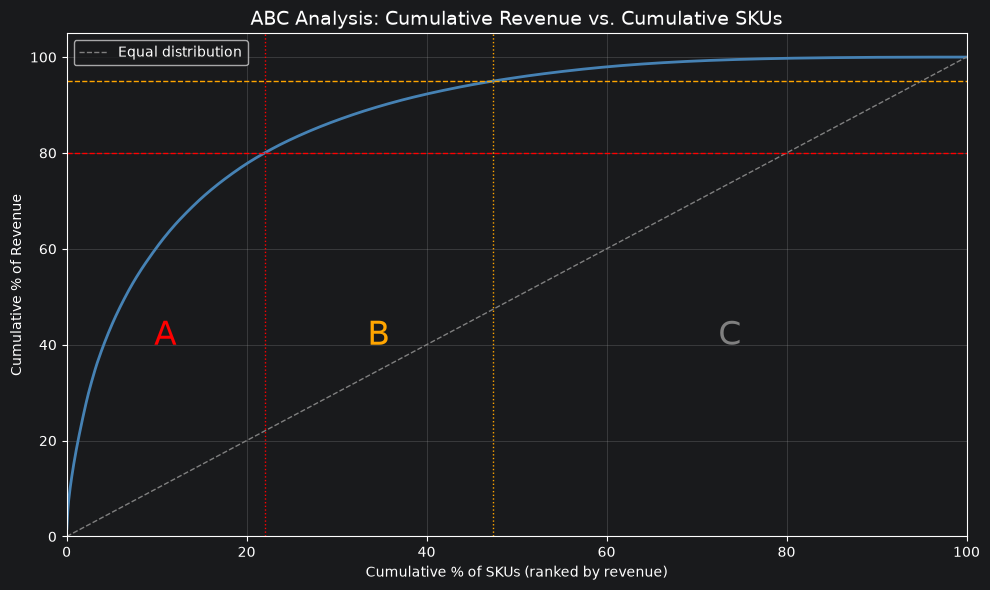

In [15]:
# ===== 第 7 步（上）：画帕累托曲线 =====

import matplotlib.pyplot as plt  # 导入画图工具，简称 plt
import os                        # 导入处理文件夹的工具

# 新建一个 images 文件夹存放图片；exist_ok=True 表示文件夹已存在也不报错
os.makedirs("images", exist_ok=True)

# 计算每个商品对应的"累计商品占比"，作为横轴
# product_sales 已经按销售额从高到低排好，行号是 0、1、2……
# 第 1 个商品 =  1/n，第 2 个 = 2/n……乘以 100 变成百分比
n = len(product_sales)
product_sales["CumProductPct"] = (product_sales.index + 1) / n * 100

# 新建一张画布：fig 是整张图，ax 是里面的坐标区域；figsize 是宽和高（英寸）
fig, ax = plt.subplots(figsize=(10, 6))

# 画曲线：横轴 = 累计商品占比，纵轴 = 累计销售额占比（乘 100 变成百分比）
ax.plot(product_sales["CumProductPct"], product_sales["CumShare"] * 100,
        color="steelblue", linewidth=2)
# 画一条从 (0,0) 到 (100,100) 的灰色斜线，代表"每个商品卖得一样多"的情况
# 实际曲线和这条线拉得越开，说明销售越集中
ax.plot([0, 100], [0, 100], color="gray", linestyle="--", linewidth=1, label="Equal distribution")
# 画两条水平虚线，标出 80% 和 95% 这两条分界线
ax.axhline(80, color="red", linestyle="--", linewidth=1)
ax.axhline(95, color="orange", linestyle="--", linewidth=1)

# 从 summary 里取出 A 类和 A+B 类的商品占比，画两条竖线把 A、B、C 区域分开
a_pct = summary.loc["A", "ProductPct"]
ab_pct = a_pct + summary.loc["B", "ProductPct"]
ax.axvline(a_pct, color="red", linestyle=":", linewidth=1)
ax.axvline(ab_pct, color="orange", linestyle=":", linewidth=1)

# 在每个区域中间写上大字母 A、B、C；ha="center" 表示文字水平居中
ax.text(a_pct / 2, 40, "A", fontsize=24, ha="center", color="red")
ax.text((a_pct + ab_pct) / 2, 40, "B", fontsize=24, ha="center", color="orange")
ax.text((ab_pct + 100) / 2, 40, "C", fontsize=24, ha="center", color="gray")

# 设置标题和坐标轴文字
ax.set_title("ABC Analysis: Cumulative Revenue vs. Cumulative SKUs", fontsize=14)
ax.set_xlabel("Cumulative % of SKUs (ranked by revenue)")
ax.set_ylabel("Cumulative % of Revenue")

# 设置坐标轴范围，并加上浅色网格线方便读数
ax.set_xlim(0, 100)
ax.set_ylim(0, 105)
ax.grid(alpha=0.3)
# 显示图例，说明灰色斜线代表什么
ax.legend()
# tight_layout 自动调整边距，防止文字被裁掉
plt.tight_layout()
# 保存图片到 images 文件夹；dpi=150 是清晰度
plt.savefig("images/pareto_curve.png", dpi=150)
plt.show()

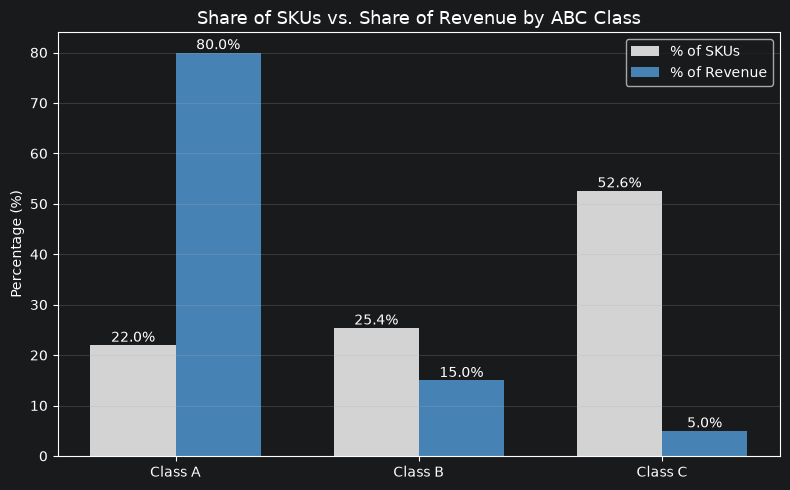

In [16]:
# ===== 第 7 步（下）：三类商品的"商品占比 vs 销售额占比"对比图 =====

fig, ax = plt.subplots(figsize=(8, 5))

# 三个类别在横轴上的位置：0、1、2
x = range(len(summary))
width = 0.35  # 每根柱子的宽度

# 每个类别画两根柱子：左边是商品占比，右边是销售额占比
# 左柱往左挪半个宽度，右柱往右挪半个宽度，两根并排
bars1 = ax.bar([i - width / 2 for i in x], summary["ProductPct"], width,
               label="% of SKUs", color="lightgray")
bars2 = ax.bar([i + width / 2 for i in x], summary["SalesPct"], width,
               label="% of Revenue", color="steelblue")

# 在每根柱子顶上标出数值，fmt 是数字格式："%.1f%%" 表示保留 1 位小数并加 % 号
ax.bar_label(bars1, fmt="%.1f%%")
ax.bar_label(bars2, fmt="%.1f%%")

# 横轴刻度显示为 Class A、Class B、Class C
ax.set_xticks(list(x))
ax.set_xticklabels(["Class " + c for c in summary.index])

ax.set_title("Share of SKUs vs. Share of Revenue by ABC Class", fontsize=13)
ax.set_ylabel("Percentage (%)")
ax.legend()  # 显示图例，说明灰色和蓝色分别代表什么
ax.grid(axis="y", alpha=0.3)  # 只加横向网格线

plt.tight_layout()
plt.savefig("images/abc_comparison.png", dpi=150)
plt.show()

## 9. 畅销商品分析

查看净销售额排名前 10 的商品，了解核心商品的特点。

In [17]:
# ===== 查看销售额排名前 10 的商品 =====

# product_sales 已经按销售额从高到低排好，head(10) 取前 10 行
# 双层方括号 [[...]] 表示只挑选这几列来显示
top10 = product_sales.head(10)[["StockCode", "Description", "TotalSales", "TotalQty", "Class"]]

# round(0) 把销售额四舍五入到整数，看起来更清爽
top10["TotalSales"] = top10["TotalSales"].round(0)
print("销售额 Top 10 商品：")
print(top10)

# ===== 把每个商品的 ABC 分类结果保存成 CSV =====
# 这份表格以后有两个用途：
#   1. 放进作品集，展示每个商品属于哪一类
#   2. 后面做 Power BI 看板时直接导入使用
product_sales.to_csv("data/abc_classification_result.csv", index=False)
print("\nABC 分类结果已保存到 data 文件夹")

销售额 Top 10 商品：
  StockCode                         Description  TotalSales  TotalQty Class
0     22423            REGENCY CAKESTAND 3 TIER    164459.0     12996     A
1    85123A  WHITE HANGING HEART T-LIGHT HOLDER     99791.0     35355     A
2     47566                       PARTY BUNTING     98244.0     18006     A
3    85099B             JUMBO BAG RED RETROSPOT     92176.0     47256     A
4     23084                  RABBIT NIGHT LIGHT     66662.0     30631     A
5     22086     PAPER CHAIN KIT 50'S CHRISTMAS      63715.0     18876     A
6     84879       ASSORTED COLOUR BIRD ORNAMENT     58792.0     36282     A
7     79321                       CHILLI LIGHTS     53747.0     10222     A
8     22197                SMALL POPCORN HOLDER     50968.0     56427     A
9     23298                      SPOTTY BUNTING     42665.0      8356     A

ABC 分类结果已保存到 data 文件夹


## 10. 结论

| 类别 | 商品数 | 商品占比 | 销售额占比 |
|---|---|---|---|
| A | 833 | 22.0% | 80.0% |
| B | 964 | 25.4% | 15.0% |
| C | 1,993 | 52.6% | 5.0% |

**主要发现**

- 22.0% 的商品贡献了 80% 的净销售额，销售高度集中，符合典型的帕累托分布
- 超过一半的商品（C 类）只贡献了 5% 的销售额
- 畅销商品集中在家居装饰、派对用品和节日礼品，其中包含明显的季节性商品
- 初版清洗因取消订单未抵消、数量录入错误，导致销售额被高估约 5%；修正后结论方向不变，但数字更准确

**库存管理建议**

- **A 类**：重点管理，提高需求预测精度和服务水平，频繁盘点，避免断货
- **B 类**：常规管理，定期检查
- **C 类**：简化管理，降低库存水平；同时评估精简品类的空间，但需注意新品、季节性商品和配套商品

**局限与后续方向**

- 仅按销售额分类，没有考虑利润、需求波动等因素，后续可结合 XYZ 分析
- 仅使用一年数据，季节性商品的判断有限
- 可针对 A 类商品进一步计算安全库存和再订货点